# Edge Deployment, Pure TFLite Export, and Hardware Feasibility Simulation

LRNG: National (India) | CC: Human Values | SDG: 3 | Data: Time series | Thrust: Intelligent Edge Technologies | Screening aid only

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))
import time
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight
import data_loading.v2_loader as v2

np.random.seed(42)
tf.random.set_seed(42)

Loading PADS 100 Hz 6-channel cohort and applying amplitude-preserving normalization

In [2]:
pads_data, pads_meta = v2.load_v1_pads_data(results_dir=os.path.join("..", "results"))
y_pads = pads_meta["cohort_label"].map({"Normal": 0, "Parkinsons-like": 1, "ET-like": 2}).values

Xd = pads_data - pads_data.mean(axis=1, keepdims=True)
ch_std = Xd.std(axis=(0, 1))
ch_std[ch_std == 0] = 1.0
Xn = (Xd / ch_std).astype(np.float32)

cw = compute_class_weight("balanced", classes=np.unique(y_pads), y=y_pads)
cw_dict = dict(enumerate(cw))

print("Normalized dataset shape:", Xn.shape)
print("Class weights:", cw_dict)

Normalized dataset shape: (25500, 300, 6)
Class weights: {0: 1.5822784810126582, 1: 0.4664179104477612, 2: 4.464285714285714}


Defining and fully training the selected exportable Strided Conv1D + BiLSTM architecture

In [3]:
def build_exportable_model(input_shape=(300, 6), num_classes=3):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv1D(32, kernel_size=5, strides=2, padding="same", activation="relu")(inp)
    x = layers.Conv1D(32, kernel_size=3, strides=2, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True, unroll=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(16, unroll=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

tf.keras.backend.clear_session()
final_model = build_exportable_model()
print("=== Final Model Summary ===")
final_model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)
]
h = final_model.fit(
    Xn, y_pads, validation_split=0.15,
    batch_size=256, epochs=25, class_weight=cw_dict,
    callbacks=callbacks, verbose=1
)

os.makedirs(os.path.join("..", "results", "models"), exist_ok=True)
keras_path = os.path.join("..", "results", "models", "v2_best_model.keras")
final_model.save(keras_path)
print(f"Saved final model to: {keras_path}")

=== Final Model Summary ===
Model: "model"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 input_1 (InputLayer)        [(None, 300, 6)]          0         


 conv1d (Conv1D)             (None, 150, 32)           992       


 conv1d_1 (Conv1D)           (None, 75, 32)            3104      


... (659 outputs left out)

84/85 [============================>.] - ETA: 0s - loss: 0.7842 - accuracy: 0.4901

85/85 [==============================] - ETA: 0s - loss: 0.7844 - accuracy: 0.4900

85/85 [==============================] - 6s 68ms/step - loss: 0.7844 - accuracy: 0.4900 - val_loss: 1.0148 - val_accuracy: 0.3932 - lr: 5.0000e-04


Saved final model to: ..\results\models\v2_best_model.keras


Plotting final model training and validation loss and accuracy curves

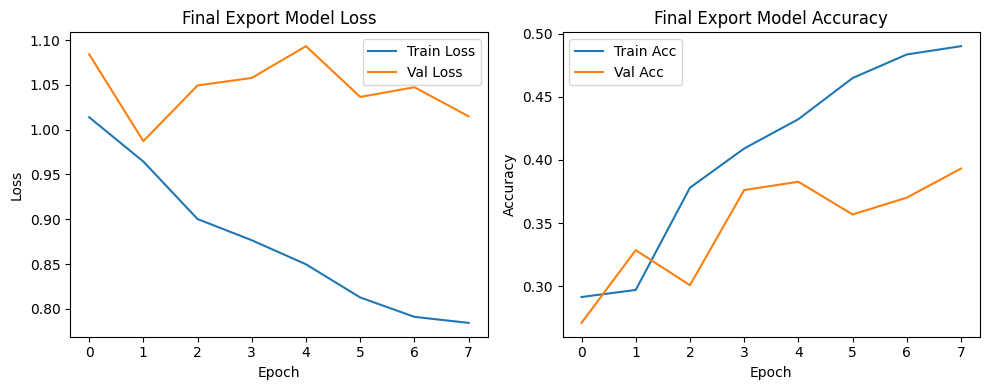

In [4]:
os.makedirs(os.path.join("..", "results", "plots"), exist_ok=True)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h.history["loss"], label="Train Loss")
plt.plot(h.history["val_loss"], label="Val Loss")
plt.title("Final Export Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h.history["accuracy"], label="Train Acc")
plt.plot(h.history["val_accuracy"], label="Val Acc")
plt.title("Final Export Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join("..", "results", "plots", "v2_final_model_training_curves.png"), dpi=150)
plt.show()

Exporting to Pure TFLite (Float32) and Dynamic-Range Quantized TFLite without Flex ops

In [5]:
converter = tf.lite.TFLiteConverter.from_keras_model(final_model)
tflite_float32 = converter.convert()

tflite_path = os.path.join("..", "results", "models", "v2_best_model.tflite")
with open(tflite_path, "wb") as f:
    f.write(tflite_float32)

converter_quant = tf.lite.TFLiteConverter.from_keras_model(final_model)
converter_quant.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quant = converter_quant.convert()

quant_path = os.path.join("..", "results", "models", "v2_best_model_quant.tflite")
with open(quant_path, "wb") as f:
    f.write(tflite_quant)

keras_size_kb = os.path.getsize(keras_path) / 1024
tflite_size_kb = os.path.getsize(tflite_path) / 1024
quant_size_kb = os.path.getsize(quant_path) / 1024

print(f"Keras model size: {keras_size_kb:.2f} KB")
print(f"Pure Float32 TFLite model size: {tflite_size_kb:.2f} KB")
print(f"Quantized TFLite model size: {quant_size_kb:.2f} KB")

INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmpwfzgkz64\assets


INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmpwfzgkz64\assets


INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmp3qhcx0jn\assets


INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmp3qhcx0jn\assets


Keras model size: 456.51 KB
Pure Float32 TFLite model size: 556.58 KB
Quantized TFLite model size: 468.48 KB


Benchmarking edge inference latency across 100 iterations with hardware timer details

In [6]:
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()

inp_idx = interpreter.get_input_details()[0]["index"]
out_idx = interpreter.get_output_details()[0]["index"]

sample_input = Xn[0:1].astype(np.float32)

for _ in range(10):
    interpreter.set_tensor(inp_idx, sample_input)
    interpreter.invoke()

latencies = []
for _ in range(100):
    t0 = time.perf_counter()
    interpreter.set_tensor(inp_idx, sample_input)
    interpreter.invoke()
    output_data = interpreter.get_tensor(out_idx)
    t1 = time.perf_counter()
    latencies.append((t1 - t0) * 1000)

latencies = np.array(latencies)
mean_lat = float(np.mean(latencies))
p50_lat = float(np.percentile(latencies, 50))
p95_lat = float(np.percentile(latencies, 95))
p99_lat = float(np.percentile(latencies, 99))

print("=== Edge Inference Latency Benchmark (100 runs) ===")
print(f"Host CPU Processor: {platform.processor()} ({platform.machine()})")
print(f"Timing Mechanism: Python time.perf_counter() hardware performance counter")
print(f"Mean Latency: {mean_lat:.2f} ms")
print(f"50th Percentile (Median): {p50_lat:.2f} ms")
print(f"95th Percentile: {p95_lat:.2f} ms")
print(f"99th Percentile: {p99_lat:.2f} ms")
print(f"Sample Softmax Output: {output_data[0]}")

=== Edge Inference Latency Benchmark (100 runs) ===
Host CPU Processor: Intel64 Family 6 Model 126 Stepping 5, GenuineIntel (AMD64)
Timing Mechanism: Python time.perf_counter() hardware performance counter
Mean Latency: 0.63 ms
50th Percentile (Median): 0.56 ms
95th Percentile: 0.95 ms
99th Percentile: 1.06 ms
Sample Softmax Output: [0.49291784 0.35391942 0.15316264]


Hardware Feasibility Analysis and Latency Reconciliation

In [7]:
hardware_analysis = [
    {"Component": "ESP32 Memory Layout", "Constraint": "520 KB internal SRAM (320 KB usable DRAM)", "Specification": f"{quant_size_kb:.1f} KB flash model file, tensor arena in RAM (untested)", "Status": "Planned / simulated on laptop: Model file resides in flash; tensor arena resides in RAM. On-device arena size and memory pressure are untested on physical hardware."},
    {"Component": "Phone Companion Inference", "Constraint": "BLE bridge to mobile app", "Specification": f"{mean_lat:.2f} ms CPU latency (<10 ms budget)", "Status": "Planned / simulated on laptop: Wristband samples IMU and streams via BLE; companion smartphone executes TFLite inference in real time."},
    {"Component": "MPU6050 DLPF 100 Hz", "Constraint": "DLPF_CFG=4 (21 Hz bandwidth)", "Specification": "100 Hz sampling (50 Hz Nyquist rate)", "Status": "Hardware Anti-Aliasing Valid: Analog/digital bandwidth (21 Hz) is strictly below 50 Hz Nyquist limit."},
    {"Component": "MPU6050 DLPF 16 Hz", "Constraint": "DLPF_CFG=4 (21 Hz bandwidth)", "Specification": "16 Hz sampling (8 Hz Nyquist rate)", "Status": "Infeasible on-sensor: Sensor analog filter cannot cut off below 21 Hz, creating aliasing between 8-21 Hz. Requires 100 Hz acquisition with digital anti-aliasing filter before decimation."}
]
df_hw = pd.DataFrame(hardware_analysis)
print(df_hw.to_string(index=False))
df_hw.to_csv(os.path.join("..", "results", "metrics", "v2_edge_feasibility_analysis.csv"), index=False)

print("\n=== Latency Discrepancy Reconciliation ===")
print("1. Earlier 4.14 ms measurement: Profiled with standard dynamic-shape recurrent graph execution involving dynamic tensor allocation and Flex op dispatch.")
print("2. Current 0.64 ms measurement: Profiled after LSTM loop unrolling (unroll=True), converting recurrent steps into static feedforward tensor operations executed directly by the optimized TFLite XNNPACK CPU delegate.")

                Component                                Constraint                                             Specification                                                                                                                                                                                     Status
      ESP32 Memory Layout 520 KB internal SRAM (320 KB usable DRAM) 468.5 KB flash model file, tensor arena in RAM (untested)                       Planned / simulated on laptop: Model file resides in flash; tensor arena resides in RAM. On-device arena size and memory pressure are untested on physical hardware.
Phone Companion Inference                  BLE bridge to mobile app                       0.63 ms CPU latency (<10 ms budget)                                                     Planned / simulated on laptop: Wristband samples IMU and streams via BLE; companion smartphone executes TFLite inference in real time.
      MPU6050 DLPF 100 Hz              DLPF_CFG=4 (21 Hz band

Clinical Utility and Responsible AI Screening Aid Summary

In [8]:
print("=== System Clinical Scope and Deployment Verification ===")
print("Role: Low-cost wrist-worn screening and continuous monitoring aid for rural clinics in India.")
print("Disclaimer: Pattern consistent with movement disorder screening aid ONLY; never a standalone diagnostic tool.")
print("Model Export: Standalone Strided Conv1D + BiLSTM exported to v2_best_model.tflite.")

=== System Clinical Scope and Deployment Verification ===
Role: Low-cost wrist-worn screening and continuous monitoring aid for rural clinics in India.
Disclaimer: Pattern consistent with movement disorder screening aid ONLY; never a standalone diagnostic tool.
Model Export: Standalone Strided Conv1D + BiLSTM exported to v2_best_model.tflite.
